In [ ]:
import sys
print(sys.executable)

C:\Users\YOHO_LAP_22\Desktop\week 3 day 5\Week3_Day5_Customer_Churn\venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("data/Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("COLUMN NAMES")
print(df.columns.tolist())

print("\nDATASET INFORMATION")
df.info()

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nBLANK TOTAL CHARGES")
print(df["TotalCharges"].astype(str).str.strip().eq("").sum())

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

COLUMN NAMES
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 n

In [5]:
print("CHURN DISTRIBUTION")
print(df["Churn"].value_counts())

print("\nCHURN PERCENTAGE")
print(df["Churn"].value_counts(normalize=True) * 100)

CHURN DISTRIBUTION
Churn
No     5174
Yes    1869
Name: count, dtype: int64

CHURN PERCENTAGE
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [6]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (5634, 20)
Testing data shape: (1409, 20)


## Project Assumptions and Evaluation Metric

### Assumptions
1. Each row represents one customer.
2. The Churn column indicates whether a customer left the company.
3. CustomerID is an identifier and is not useful for prediction.
4. Historical customer behavior can help predict future churn.
5. The test dataset will remain untouched until final evaluation.

### Evaluation Metrics
- Primary metric: ROC-AUC
- Secondary metric: F1-score

ROC-AUC measures how well the model distinguishes between customers who churn and customers who stay across different classification thresholds.

F1-score balances precision and recall. It is useful when the churn classes are imbalanced.

In [7]:
eda_df = X_train.copy()
eda_df["Churn"] = y_train

print("EDA dataset shape:", eda_df.shape)

EDA dataset shape: (5634, 21)


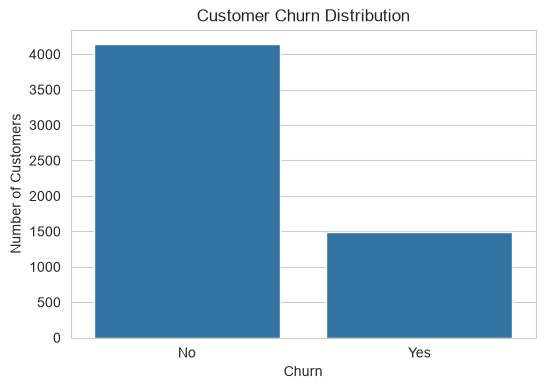

In [8]:
plt.figure(figsize=(6, 4))

sns.countplot(data=eda_df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

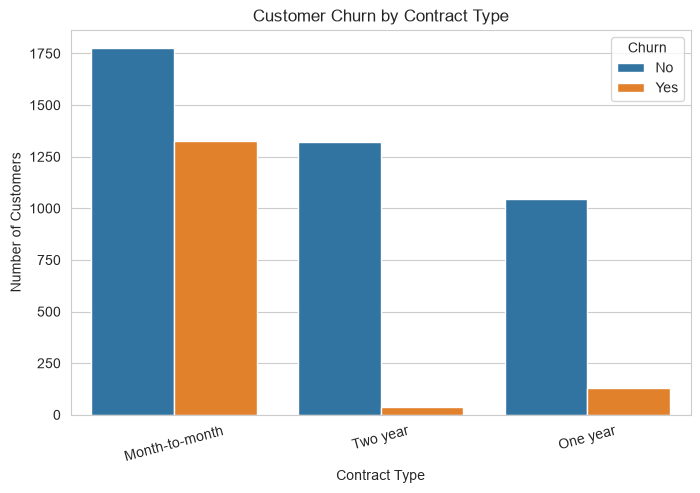

In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(data=eda_df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.show()

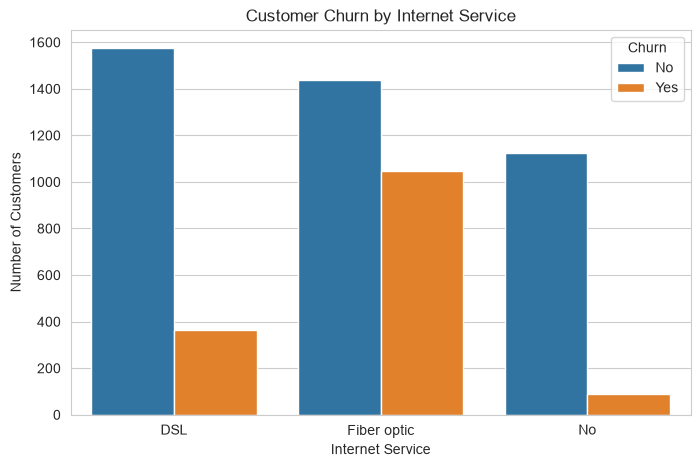

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(data=eda_df, x="InternetService", hue="Churn")

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

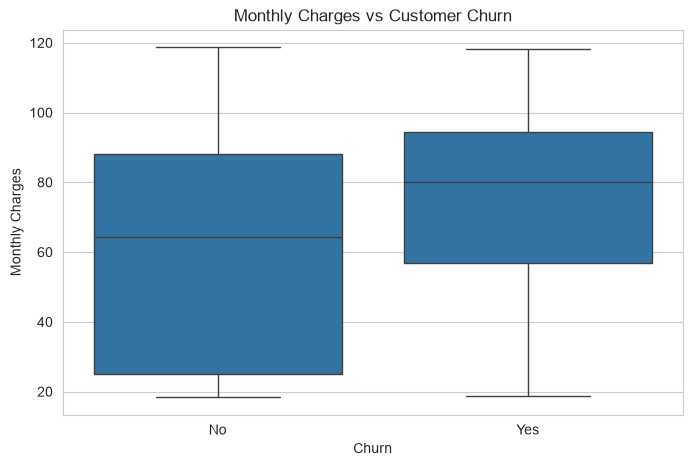

In [11]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=eda_df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

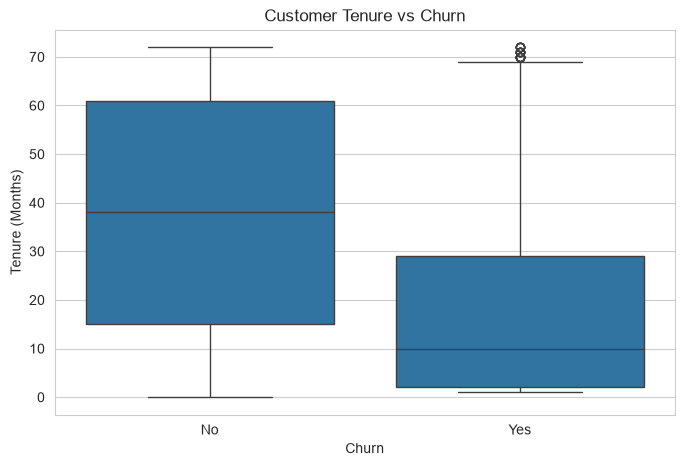

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=eda_df, x="Churn", y="tenure")

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

In [13]:
# Work on copies of the training data
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

# Convert TotalCharges to numeric
X_train_clean["TotalCharges"] = pd.to_numeric(
    X_train_clean["TotalCharges"], errors="coerce"
)

X_test_clean["TotalCharges"] = pd.to_numeric(
    X_test_clean["TotalCharges"], errors="coerce"
)

# Calculate median using training data only
total_charges_median = X_train_clean["TotalCharges"].median()

# Fill missing values in both datasets
X_train_clean["TotalCharges"] = X_train_clean["TotalCharges"].fillna(total_charges_median)
X_test_clean["TotalCharges"] = X_test_clean["TotalCharges"].fillna(total_charges_median)

# Remove customer ID because it is only an identifier
X_train_clean = X_train_clean.drop(columns=["customerID"])
X_test_clean = X_test_clean.drop(columns=["customerID"])

print("Training data cleaned:", X_train_clean.shape)
print("Testing data prepared:", X_test_clean.shape)
print("Missing training values:", X_train_clean.isnull().sum().sum())

Training data cleaned: (5634, 19)
Testing data prepared: (1409, 19)
Missing training values: 0


In [14]:
def create_features(data):
    data = data.copy()

    # Feature 1: Total number of services used
    service_columns = [
        "PhoneService",
        "MultipleLines",
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
        "StreamingTV",
        "StreamingMovies"
    ]

    data["TotalServices"] = sum(
        (data[col] == "Yes").astype(int)
        for col in service_columns
    )

    # Feature 2: Customer tenure category
    data["TenureGroup"] = pd.cut(
        data["tenure"],
        bins=[-1, 12, 24, 48, float("inf")],
        labels=["New", "Medium", "Long", "Very Long"]
    )

    # Feature 3: Month-to-month contract indicator
    data["IsMonthToMonth"] = (
        data["Contract"] == "Month-to-month"
    ).astype(int)

    # Feature 4: Average monthly spend
    data["AverageMonthlySpend"] = (
        data["TotalCharges"] / data["tenure"].replace(0, np.nan)
    ).fillna(0)

    # Feature 5: Family support indicator
    data["HasFamily"] = (
        (data["Partner"] == "Yes") &
        (data["Dependents"] == "Yes")
    ).astype(int)

    return data


X_train_fe = create_features(X_train_clean)
X_test_fe = create_features(X_test_clean)

print("Feature engineering completed!")
print("Training shape:", X_train_fe.shape)
print("Testing shape:", X_test_fe.shape)

print("\nNew features:")
print([
    "TotalServices",
    "TenureGroup",
    "IsMonthToMonth",
    "AverageMonthlySpend",
    "HasFamily"
])

Feature engineering completed!
Training shape: (5634, 24)
Testing shape: (1409, 24)

New features:
['TotalServices', 'TenureGroup', 'IsMonthToMonth', 'AverageMonthlySpend', 'HasFamily']


In [16]:
numeric_features = X_train_fe.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train_fe.select_dtypes(
    include=["object", "category", "str", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'TotalServices', 'IsMonthToMonth', 'AverageMonthlySpend', 'HasFamily']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both transformations
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [20]:
import sklearn
print("Scikit-learn version:", sklearn.__version__)
print("Scikit-learn location:", sklearn.__file__)

Scikit-learn version: 1.9.1
Scikit-learn location: C:\Users\YOHO_LAP_22\Desktop\week 3 day 5\Week3_Day5_Customer_Churn\venv\Lib\site-packages\sklearn\__init__.py


In [21]:
%pip install --upgrade --force-reinstall scikit-learn

  Using cached scikit_learn-1.9.1-cp315-cp315-win_amd64.whl.metadata (9.3 kB)
  Using cached numpy-2.5.5-cp315-cp315-win_amd64.whl.metadata (6.6 kB)
  Using cached scipy-1.18.1-cp315-cp315-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp315-cp315-win_amd64.whl (8.4 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached narwhals-2.28.0-py3-none-any.whl (490 kB)
Using cached numpy-2.5.5-cp315-cp315-win_amd64.whl (12.7 MB)
Using cached scipy-1.18.1-cp315-cp315-win_amd64.whl (37.4 MB)
Using cached threadpoolctl-3.8.0-py3-none-any.whl (32 kB)

  Attempting uninstall: threadpoolctl

    Found existing installation: threadpoolctl 3.8.0

    Uninst

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.


In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import roc_auc_score, f1_score, classification_report

print("All machine learning imports successful!")

All machine learning imports successful!


In [24]:
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

print("Logistic Regression pipeline created!")
print("Random Forest pipeline created!")

Logistic Regression pipeline created!
Random Forest pipeline created!


In [25]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "roc_auc": "roc_auc",
    "f1": "f1"
}

print("5-fold cross-validation configured!")

5-fold cross-validation configured!


In [26]:
logistic_scores = cross_validate(
    logistic_pipeline,
    X_train_fe,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("LOGISTIC REGRESSION RESULTS")
print("Mean ROC-AUC:", logistic_scores["test_roc_auc"].mean())
print("Mean F1-score:", logistic_scores["test_f1"].mean())

LOGISTIC REGRESSION RESULTS
Mean ROC-AUC: 0.8454994685898516
Mean F1-score: nan


In [27]:
rf_scores = cross_validate(
    random_forest_pipeline,
    X_train_fe,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("RANDOM FOREST RESULTS")
print("Mean ROC-AUC:", rf_scores["test_roc_auc"].mean())
print("Mean F1-score:", rf_scores["test_f1"].mean())

RANDOM FOREST RESULTS
Mean ROC-AUC: 0.8277284132222495
Mean F1-score: nan


In [28]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Mean ROC-AUC": [
        logistic_scores["test_roc_auc"].mean(),
        rf_scores["test_roc_auc"].mean()
    ],
    "Mean F1-Score": [
        logistic_scores["test_f1"].mean(),
        rf_scores["test_f1"].mean()
    ]
})

results

,Model,Mean ROC-AUC,Mean F1-Score
0,Logistic Regression,0.845499,NaN
1,Random Forest,0.827728,NaN


In [29]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Mean ROC-AUC": [
        logistic_scores["test_roc_auc"].mean(),
        rf_scores["test_roc_auc"].mean()
    ],
    "Mean F1-Score": [
        logistic_scores["test_f1"].mean(),
        rf_scores["test_f1"].mean()
    ]
})

results = results.round(4)

display(results)

,Model,Mean ROC-AUC,Mean F1-Score
0,Logistic Regression,0.8455,NaN
1,Random Forest,0.8277,NaN


In [30]:
from sklearn.metrics import make_scorer

scoring = {
    "roc_auc": "roc_auc",
    "f1": make_scorer(f1_score, pos_label="Yes")
}

print("F1 scoring corrected: Yes = customer churn")

F1 scoring corrected: Yes = customer churn


In [31]:
logistic_scores = cross_validate(
    logistic_pipeline,
    X_train_fe,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Logistic Regression ROC-AUC:",
      logistic_scores["test_roc_auc"].mean())

print("Logistic Regression F1:",
      logistic_scores["test_f1"].mean())

Logistic Regression ROC-AUC: 0.8454994685898516
Logistic Regression F1: 0.593759164204032


In [32]:
rf_scores = cross_validate(
    random_forest_pipeline,
    X_train_fe,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Random Forest ROC-AUC:",
      rf_scores["test_roc_auc"].mean())

print("Random Forest F1:",
      rf_scores["test_f1"].mean())

Random Forest ROC-AUC: 0.8277284132222495
Random Forest F1: 0.6100822792891707


In [33]:
dummy_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DummyClassifier(strategy="prior"))
])

dummy_scores = cross_validate(
    dummy_pipeline,
    X_train_fe,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Dummy Classifier ROC-AUC:",
      dummy_scores["test_roc_auc"].mean())

print("Dummy Classifier F1:",
      dummy_scores["test_f1"].mean())

Dummy Classifier ROC-AUC: 0.5
Dummy Classifier F1: 0.0


In [34]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Dummy Classifier"
    ],
    "Mean ROC-AUC": [
        logistic_scores["test_roc_auc"].mean(),
        rf_scores["test_roc_auc"].mean(),
        dummy_scores["test_roc_auc"].mean()
    ],
    "Mean F1-Score": [
        logistic_scores["test_f1"].mean(),
        rf_scores["test_f1"].mean(),
        dummy_scores["test_f1"].mean()
    ]
})

results = results.round(4)

display(results)

,Model,Mean ROC-AUC,Mean F1-Score
0,Logistic Regression,0.8455,0.5938
1,Random Forest,0.8277,0.6101
2,Dummy Classifier,0.5000,0.0000


In [35]:
best_model = logistic_pipeline

best_model.fit(X_train_fe, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predictions
y_pred = best_model.predict(X_test_fe)

# Find probability column for churn = Yes
yes_index = list(best_model.named_steps["model"].classes_).index("Yes")
y_proba = best_model.predict_proba(X_test_fe)[:, yes_index]

# Evaluation metrics
test_roc_auc = roc_auc_score(y_test, y_proba)
test_f1 = f1_score(y_test, y_pred, pos_label="Yes")

print("FINAL TEST RESULTS")
print("-------------------")
print("ROC-AUC:", round(test_roc_auc, 4))
print("F1-Score:", round(test_f1, 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred))

FINAL TEST RESULTS
-------------------
ROC-AUC: 0.8421
F1-Score: 0.5753

CLASSIFICATION REPORT
              precision    recall  f1-score   support

          No       0.84      0.90      0.87      1035
         Yes       0.65      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



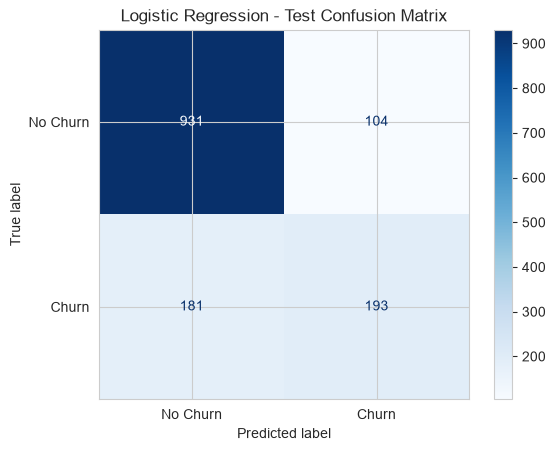

In [37]:
cm = confusion_matrix(y_test, y_pred, labels=["No", "Yes"])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

display.plot(cmap="Blues")
plt.title("Logistic Regression - Test Confusion Matrix")
plt.show()

In [38]:
results.to_csv("results/model_comparison.csv", index=False)

print("Model comparison saved successfully!")

Model comparison saved successfully!
